# Llama 3 line likelihoods on MR-GSM8K

Sample 100 `question_type=original` examples from `Randolphzeng/Mr-GSM8K` and score every supplied solution step under `meta-llama/Meta-Llama-3-8B-Instruct`. Each token is scored causally given the chat-formatted question and all preceding solution tokens.

In [1]:
import ast
import os
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import torch
import torch.nn.functional as F
from datasets import load_dataset
from dotenv import load_dotenv
from huggingface_hub import login
from IPython.display import display
from tqdm.auto import tqdm
from transformers import AutoModelForCausalLM, AutoTokenizer

load_dotenv("../secret.env")
assert os.environ.get("HF_TOKEN", "").startswith("hf_"), "No HF_TOKEN configured"
login(token=os.environ["HF_TOKEN"])

Note: Environment variable`HF_TOKEN` is set and is the current active token independently from the token you've just configured.


In [2]:
MODEL_ID = "meta-llama/Meta-Llama-3-8B-Instruct"
DATASET_ID = "Randolphzeng/Mr-GSM8K"
SAMPLE_SIZE = 100
SEED = 42
CACHE_PATH = Path("cache") / f"llama_3_mr_gsm8k_original_n{SAMPLE_SIZE}_seed{SEED}_step_scores.csv"

if CACHE_PATH.exists():
    print(f"Found inference cache at {CACHE_PATH.resolve()}; model loading will be skipped.")
else:
    assert torch.cuda.is_available(), "CUDA not available"
    dtype = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16

    tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, token=os.environ["HF_TOKEN"])
    assert tokenizer.is_fast, "A fast tokenizer is required for offset mappings"
    model = AutoModelForCausalLM.from_pretrained(
        MODEL_ID,
        token=os.environ["HF_TOKEN"],
        torch_dtype=dtype,
        device_map="auto",
        low_cpu_mem_usage=True,
    )
    model.eval()
    input_device = model.get_input_embeddings().weight.device
    print(f"Loaded {MODEL_ID} on {input_device} using {dtype}.")

Found inference cache at /sc/home/jan.berndt/better-nli/mr-gsm8k/cache/llama_3_mr_gsm8k_original_n100_seed42_step_scores.csv; model loading will be skipped.


## Load and sample the dataset

In [3]:
dataset = load_dataset(DATASET_ID, split="test", token=os.environ["HF_TOKEN"])
original = dataset.filter(lambda row: row["question_type"] == "original")
assert len(original) >= SAMPLE_SIZE
sample = original.shuffle(seed=SEED).select(range(SAMPLE_SIZE))
assert len(sample) == SAMPLE_SIZE
assert set(sample["question_type"]) == {"original"}
print(f"Sampled {len(sample)} of {len(original)} original questions (seed={SEED}).")
display(sample.select(range(3)).to_pandas()[["uuid", "question", "model_output_steps", "model_output_solution_correctness"]])

Sampled 100 of 1418 original questions (seed=42).


,uuid,question,model_output_steps,model_output_solution_correctness
0,6000dd45-9b87-4aa1-8be3-0ee9343c15b9,Each class in a school has 20 students. There ...,['Step 1: We know that each class has 20 stude...,correct
1,639c26de-f3e5-4027-a82c-cc3746ea53b6,A shop sells school supplies. One notebook is ...,"['Step 1: Daniel wants to buy 5 notebooks, so ...",correct
2,0a71e234-b79c-4ace-944b-d0294c0f69db,If Sam and Harry have 100 feet of fence betwee...,['Step 1: We know that Sam and Harry agreed t...,wrong


## Score supplied answer steps

`model_output_steps` is stored in the Hub CSV as a Python-list string. The scorer parses that list, joins its entries with newlines, and uses the Llama 3 chat template for the question prefix. The first run writes scores atomically to `CACHE_PATH`; later runs validate and reuse that file without loading the model. Delete the cache file to force recomputation.

In [4]:
INSTRUCTION = (
    "Solve the following math problem. Write the solution in logical steps labeled "
    "'Step 1:', 'Step 2:', and so on. On the final step, output the numeric answer "
    "prefixed with '####'."
)

def parse_steps(value):
    steps = ast.literal_eval(value) if isinstance(value, str) else list(value)
    assert steps and all(isinstance(step, str) and step.startswith("Step ") for step in steps)
    return steps

def format_question(question):
    messages = [{"role": "user", "content": f"{INSTRUCTION}\n\nQuestion:\n{question}"}]
    return tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=True)

def score_steps(question, raw_steps):
    steps = parse_steps(raw_steps)
    prompt = format_question(question)
    answer = "\n".join(steps)
    text = prompt + answer
    encoded = tokenizer(
        text,
        add_special_tokens=False,
        return_offsets_mapping=True,
        return_tensors="pt",
    )
    offsets = encoded.pop("offset_mapping")[0].tolist()
    assert encoded["input_ids"].shape[1] <= model.config.max_position_embeddings
    model_inputs = {name: tensor.to(input_device) for name, tensor in encoded.items()}

    with torch.inference_mode():
        logits = model(**model_inputs, use_cache=False).logits
        token_log_probs = -F.cross_entropy(
            logits[:, :-1, :].transpose(1, 2),
            model_inputs["input_ids"][:, 1:],
            reduction="none",
        )[0].float().cpu()

    rows = []
    cursor = len(prompt)
    for step_number, step_text in enumerate(steps, start=1):
        step_start = cursor
        step_end = step_start + len(step_text)
        token_positions = [
            position
            for position, (start, end) in enumerate(offsets)
            if position > 0 and end > step_start and start < step_end and end > start
        ]
        assert token_positions, f"No scoreable tokens in step {step_number}"
        step_log_probs = torch.stack([token_log_probs[position - 1] for position in token_positions])
        rows.append({
            "step": step_number,
            "text": step_text,
            "tokens": len(token_positions),
            "average_likelihood": step_log_probs.exp().mean().item(),
            "average_log_likelihood": step_log_probs.mean().item(),
        })
        cursor = step_end + 1
    assert cursor - 1 == len(text)
    return rows

In [5]:
metadata_columns = [
    "uuid",
    "question_type",
    "ground_truth_answer",
    "model_output_answer_correctness",
    "model_output_solution_correctness",
    "model_output_solution_first_error_step",
]
required_cache_columns = {
    "sample_index",
    *metadata_columns,
    "step",
    "text",
    "tokens",
    "average_likelihood",
    "average_log_likelihood",
}
expected_uuids = set(sample["uuid"])

if CACHE_PATH.exists():
    step_scores = pd.read_csv(CACHE_PATH)
    assert required_cache_columns <= set(step_scores.columns), "Cache schema does not match this notebook"
    assert set(step_scores["uuid"]) == expected_uuids, "Cache does not match the deterministic sample"
    assert step_scores["uuid"].nunique() == SAMPLE_SIZE
    print(f"Loaded {len(step_scores)} scored steps from {CACHE_PATH.resolve()}")
else:
    all_rows = []
    for sample_index, example in enumerate(tqdm(sample, total=SAMPLE_SIZE)):
        scored_steps = score_steps(example["question"], example["model_output_steps"])
        metadata = {column: example[column] for column in metadata_columns}
        for row in scored_steps:
            all_rows.append({"sample_index": sample_index, **metadata, **row})

    step_scores = pd.DataFrame(all_rows)
    assert step_scores["uuid"].nunique() == SAMPLE_SIZE
    assert set(step_scores["uuid"]) == expected_uuids

    CACHE_PATH.parent.mkdir(parents=True, exist_ok=True)
    temporary_path = CACHE_PATH.with_suffix(CACHE_PATH.suffix + ".tmp")
    step_scores.to_csv(temporary_path, index=False)
    temporary_path.replace(CACHE_PATH)
    print(f"Saved {len(step_scores)} scored steps to {CACHE_PATH.resolve()}")

display(step_scores.head().style.format({"average_likelihood": "{:.6f}", "average_log_likelihood": "{:.4f}"}))

Loaded 703 scored steps from /sc/home/jan.berndt/better-nli/mr-gsm8k/cache/llama_3_mr_gsm8k_original_n100_seed42_step_scores.csv


,sample_index,uuid,question_type,ground_truth_answer,model_output_answer_correctness,model_output_solution_correctness,model_output_solution_first_error_step,step,text,tokens,average_likelihood,average_log_likelihood
0,0,6000dd45-9b87-4aa1-8be3-0ee9343c15b9,original,17,correct,correct,nan,1,Step 1: We know that each class has 20 students.,14,0.731266,-1.4162
1,0,6000dd45-9b87-4aa1-8be3-0ee9343c15b9,original,17,correct,correct,nan,2,Step 2: The total number of students in the three classes is 20 * 3 = 60.,23,0.766679,-0.5049
2,0,6000dd45-9b87-4aa1-8be3-0ee9343c15b9,original,17,correct,correct,nan,3,Step 3: We also know that the school is 50% boys and 50% girls.,21,0.826055,-0.3633
3,0,6000dd45-9b87-4aa1-8be3-0ee9343c15b9,original,17,correct,correct,nan,4,"Step 4: So, the number of boys in the three classes is 60 * 50% = 30.",25,0.766734,-0.5009
4,0,6000dd45-9b87-4aa1-8be3-0ee9343c15b9,original,17,correct,correct,nan,5,Step 5: We are given that the first class has 15 girls and the second class has 12 girls.,24,0.887812,-0.1897


## Summarize the 100 examples

In [6]:
question_scores = (
    step_scores.assign(
        weighted_log_likelihood=lambda frame: frame["tokens"] * frame["average_log_likelihood"]
    )
    .groupby(["sample_index", "uuid", "model_output_solution_correctness"], as_index=False)
    .agg(
        steps=("step", "count"),
        tokens=("tokens", "sum"),
        average_step_likelihood=("average_likelihood", "mean"),
        weighted_log_likelihood=("weighted_log_likelihood", "sum"),
    )
)
question_scores["average_token_log_likelihood"] = (
    question_scores["weighted_log_likelihood"] / question_scores["tokens"]
)
question_scores["perplexity"] = torch.exp(
    -torch.tensor(question_scores["average_token_log_likelihood"].to_numpy())
).numpy()
display(question_scores.describe(include="all"))

,sample_index,uuid,model_output_solution_correctness,steps,tokens,average_step_likelihood,weighted_log_likelihood,average_token_log_likelihood,perplexity
count,100.000000,100,100,100.00000,100.000000,100.000000,100.000000,100.000000,100.000000
unique,NaN,100,2,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,6000dd45-9b87-4aa1-8be3-0ee9343c15b9,wrong,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,1,57,NaN,NaN,NaN,NaN,NaN,NaN
mean,49.500000,NaN,NaN,7.03000,161.320000,0.766347,-99.712564,-0.678708,2.265652
std,29.011492,NaN,NaN,2.64558,70.548626,0.053241,45.447623,0.382559,2.685641
min,0.000000,NaN,NaN,2.00000,33.000000,0.563849,-281.814038,-3.326351,1.343219
25%,24.750000,NaN,NaN,5.00000,114.000000,0.745248,-110.634159,-0.703268,1.636923
50%,49.500000,NaN,NaN,7.00000,144.000000,0.775330,-88.992116,-0.590434,1.804773
75%,74.250000,NaN,NaN,8.00000,185.250000,0.796040,-70.208758,-0.492801,2.020375


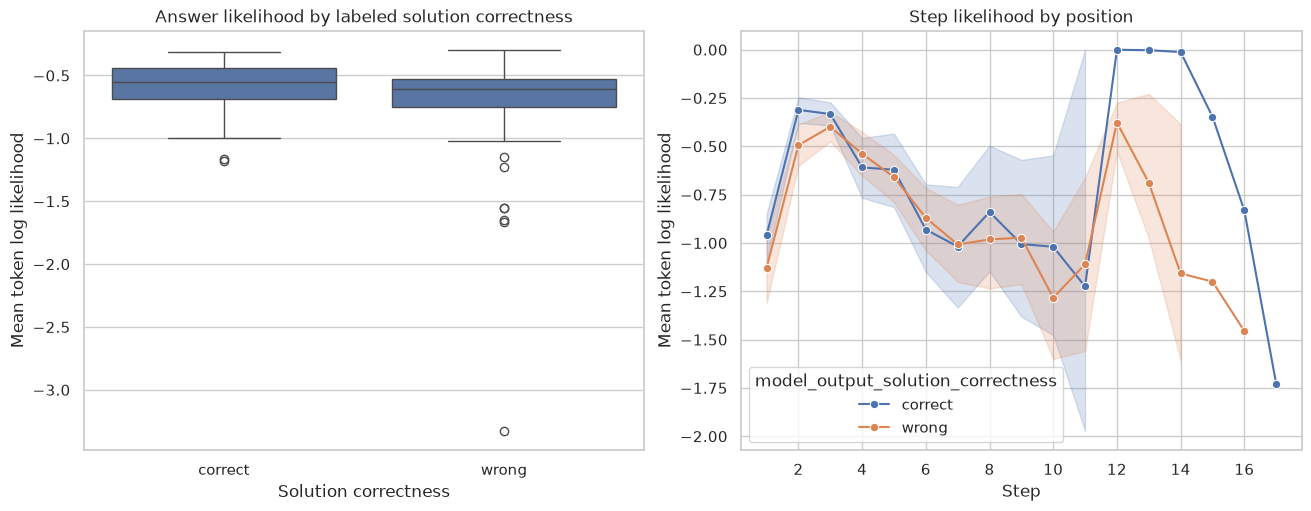

In [7]:
sns.set_theme(style="whitegrid", context="notebook")
fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
sns.boxplot(
    data=question_scores,
    x="model_output_solution_correctness",
    y="average_token_log_likelihood",
    ax=axes[0],
)
axes[0].set_title("Answer likelihood by labeled solution correctness")
axes[0].set_xlabel("Solution correctness")
axes[0].set_ylabel("Mean token log likelihood")

sns.lineplot(
    data=step_scores,
    x="step",
    y="average_log_likelihood",
    hue="model_output_solution_correctness",
    marker="o",
    errorbar=("ci", 95),
    ax=axes[1],
)
axes[1].set_title("Step likelihood by position")
axes[1].set_xlabel("Step")
axes[1].set_ylabel("Mean token log likelihood")
plt.show()

## Correct versus first incorrect steps

MR-GSM8K labels the first erroneous step rather than every step independently. Steps before the first error are treated as correct, the labeled first-error step as incorrect, and subsequent steps are excluded. Every step in a correct solution is treated as correct.

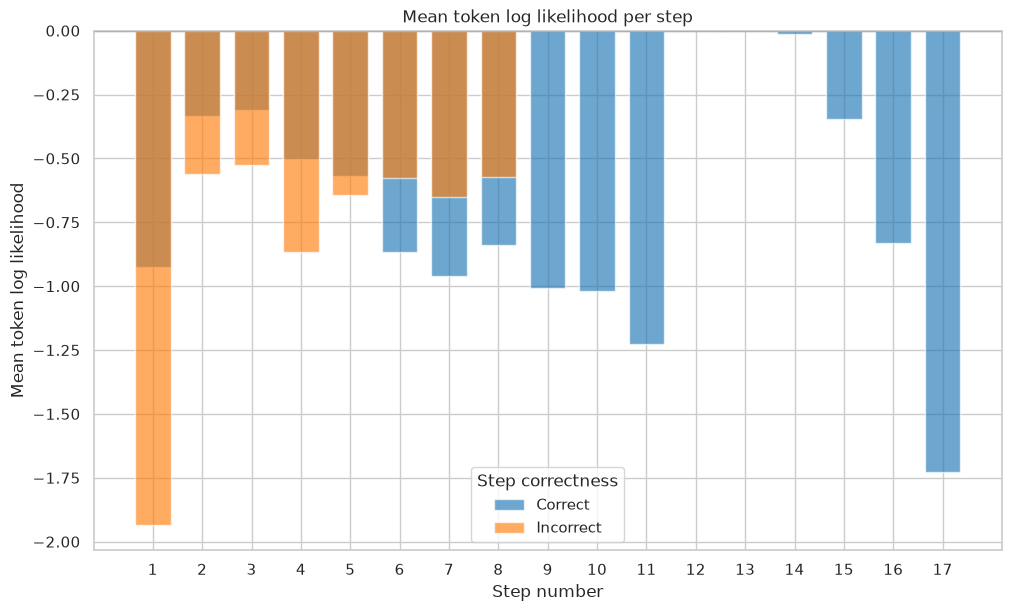

In [10]:
wrong_solution = step_scores["model_output_solution_correctness"].eq("wrong")
first_error_step = pd.to_numeric(
    step_scores["model_output_solution_first_error_step"], errors="coerce"
)
assert first_error_step[wrong_solution].notna().all()
assert (first_error_step[wrong_solution] % 1 == 0).all()

step_scores["step_correctness"] = "correct"
step_scores.loc[
    wrong_solution & step_scores["step"].eq(first_error_step),
    "step_correctness",
] = "incorrect"
step_scores.loc[
    wrong_solution & step_scores["step"].gt(first_error_step),
    "step_correctness",
] = pd.NA

labeled_step_scores = step_scores.dropna(subset=["step_correctness"])
mean_ll_by_step = (
    labeled_step_scores.groupby(["step", "step_correctness"])["average_log_likelihood"]
    .mean()
    .unstack()
)

fig, ax = plt.subplots(figsize=(10, 6), constrained_layout=True)
colors = {"correct": "tab:blue", "incorrect": "tab:orange"}
for label in ["correct", "incorrect"]:
    values = mean_ll_by_step[label].dropna()
    ax.bar(
        values.index,
        values,
        width=0.72,
        alpha=0.65,
        color=colors[label],
        label=label.capitalize(),
    )

ax.set_title("Mean token log likelihood per step")
ax.set_xlabel("Step number")
ax.set_ylabel("Mean token log likelihood")
ax.set_xticks(sorted(labeled_step_scores["step"].unique()))
ax.axhline(0, color="black", linewidth=0.8)
ax.legend(title="Step correctness")
plt.show()

In [9]:
display(
    step_scores.nsmallest(10, "average_log_likelihood")[
        ["uuid", "step", "text", "model_output_solution_correctness", "average_log_likelihood"]
    ].style.format({"average_log_likelihood": "{:.4f}"})
)


,uuid,step,text,model_output_solution_correctness,average_log_likelihood
58,2e77112e-7b76-4426-89b0-9bd3f6db6e9f,1,Step 1: We have 600 inches / 30 inches/day = <<600/30=20>>20 days.,wrong,-3.6924
21,0a71e234-b79c-4ace-944b-d0294c0f69db,1,"Step 1: We know that Sam and Harry agreed to split the fence, so they each got 100/2 = <<100/2=50>>50 feet of fence.",wrong,-3.0263
91,e2e5b550-724d-4c3b-9d60-4f3c6487ecf5,1,Step 1: We know that Anna has $16 - $4 = $<<16-4=12>>12 left in her budget.,correct,-2.9255
236,8eb87f9c-a87f-480d-9535-9595eb768e52,1,"Step 1: We know that distance = speed * time. So, if we put this in this case, we get distance = 50km/hr * 3 days = <<50*3=150>>150 km.",wrong,-2.6205
340,a4917412-bce0-40f3-a786-6dddfe05909e,1,"Step 1: First, figure out how much Nancy owes per book by multiplying the fine per day by the number of days late: .50 * 7 = $<<.50*7=3.50>>3.50",wrong,-2.5230
556,a15e514c-3135-4f37-afcc-2a587784f377,1,Step 1: We know he spent $27000 and that he can buy 100 books for $500. So 27000/500 = <<27000/500=54>>54 books,wrong,-2.3740
443,e24fba0b-630c-41d5-a50d-975d877df908,1,Step 1: He had to walk to the store which is 4 miles from his house so that's 4 miles there and 4 miles back for a total of 4+4 = <<4+4=8>>8 miles,wrong,-2.3614
617,7e3ba824-fb5c-4910-9f8c-138ac5621f53,10,Step 10: The answer is: 120,wrong,-2.0312
275,a6cbaaf5-0b15-4174-a1a9-54ec38d004c2,1,"Step 1: First, we need to find the volume of the pool. To do this, we will multiply the length times the width times the height, or 25*14*4=<<25*14*4=350>>350 cubic feet.",wrong,-2.0308
474,85ee9801-37f1-41e3-bcee-e2922b2d6474,2,"Step 2: She earns $10 an hour from wages, so she earns 10 * 40 = $<<10*40=400>>400 from wages per week.",wrong,-2.0260
